In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

/home/saeeb/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-5xl9hed3 because there was an issue with the default path (/home/saeeb/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
df = pd.read_csv("armPrediction.csv")

In [3]:
df.head()

,Attendance,MSE,HRS,ESE
0,70,10,17,42
1,92,7,20,39
2,67,3,18,32
3,82,16,13,50
4,80,9,10,44


In [4]:
df.columns

Index(['Attendance', 'MSE', 'HRS', 'ESE'], dtype='str')

In [5]:
df.dropna()

,Attendance,MSE,HRS,ESE
0,70,10,17,42
1,92,7,20,39
2,67,3,18,32
3,82,16,13,50
4,80,9,10,44
...,...,...,...,...
68,80,10,19,47
69,78,8,18,40
70,92,9,8,49
71,78,11,6,53


In [6]:
correlation_matrix = df.corr()
print(correlation_matrix)

            Attendance       MSE       HRS       ESE
Attendance    1.000000 -0.080943 -0.165307 -0.109972
MSE          -0.080943  1.000000  0.177060  0.751530
HRS          -0.165307  0.177060  1.000000  0.255632
ESE          -0.109972  0.751530  0.255632  1.000000


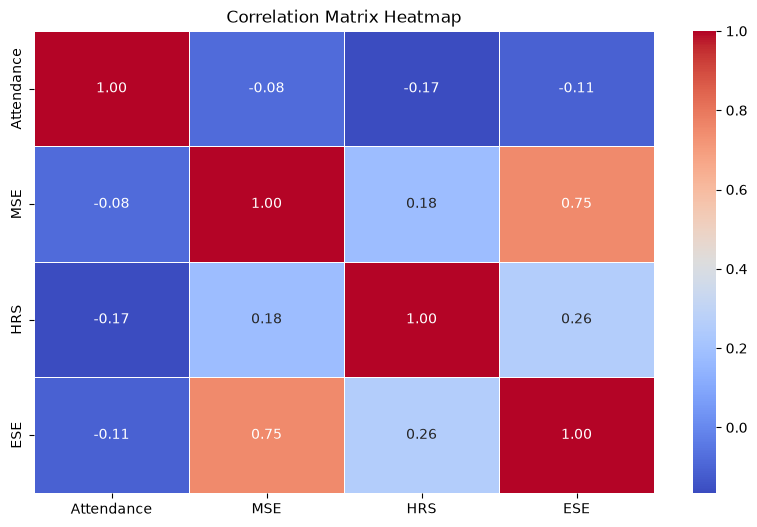

In [7]:
plt.figure(figsize=(10,6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.show()

In [8]:
x = df[['Attendance', 'MSE', 'HRS']]

In [9]:
y = df['ESE']

In [10]:
x

,Attendance,MSE,HRS
0,70,10,17
1,92,7,20
2,67,3,18
3,82,16,13
4,80,9,10
...,...,...,...
68,80,10,19
69,78,8,18
70,92,9,8
71,78,11,6


In [11]:
y

0     42
1     39
2     32
3     50
4     44
      ..
68    47
69    40
70    49
71    53
72    58
Name: ESE, Length: 73, dtype: int64

In [12]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [13]:
model = LinearRegression()

In [14]:
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[-0.06, 1.69, 0.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Attendance','MSE','HRS']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,33.41
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [15]:
y_pred = model.predict(x_test)

In [16]:
mse = mean_squared_error(y_test, y_pred)

In [17]:
print(mse)

18.581809990365336


In [18]:
r2 = r2_score(y_test, y_pred)

In [19]:
print(r2)

0.5272606006521708


In [20]:
print(model.coef_)
print(model.intercept_)

[-0.05528996  1.68654054  0.10365134]
33.41188138692076


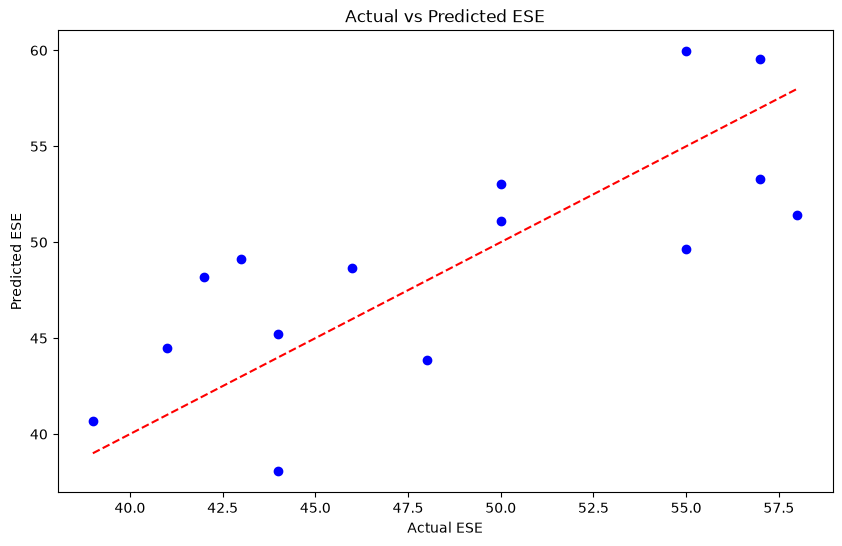

In [21]:
plt.figure(figsize=(10,6))
plt.scatter(y_test, y_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='dashed')
plt.xlabel("Actual ESE")
plt.ylabel("Predicted ESE")
plt.title("Actual vs Predicted ESE")
plt.show()

In [22]:
new_sample = pd.DataFrame([[75, 12, 18]], columns=x.columns)
prediction = model.predict(new_sample)
print(f"Predicted Output: {prediction[0]}")

Predicted Output: 51.36934476591874
